\begin{center}
{\LARGE \textbf{EN3160 Image Processing and Machine Vision}}\\[0.5em]
{\Large Assignment 2 -- Fitting and Alignment}\\[1.5em]

\textbf{Name:} S.A.D. Priyadarshana\\[0.3em]
\textbf{Index:} 230502X\\[0.3em]
\textbf{GitHub:} \href{https://github.com/denethp/CV-Assignment-02}{denethp/CV-Assignment-02}
\end{center}

\vspace{1em}

$\underline{\textbf{Question 1}}$

In [87]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

%matplotlib inline

In [88]:
def log_kernel(sigma):
    # Scale-normalized LoG, window of +-3 sigma;
    # mean removed so the truncated kernel gives zero response on flat regions.
    hw = int(np.ceil(3 * sigma))
    X, Y = np.meshgrid(np.arange(-hw, hw + 1), np.arange(-hw, hw + 1))
    log = 1 / (2 * np.pi * sigma ** 2) * (X ** 2 / sigma ** 2 + Y ** 2 / sigma ** 2 - 2) \
          * np.exp(-(X ** 2 + Y ** 2) / (2 * sigma ** 2))
    return log - log.mean()

In [89]:
im = cv.imread('images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

sigmas = np.arange(1, 16.5, 0.5)
scale_space = np.stack([cv.filter2D(gray, -1, log_kernel(s)) for s in sigmas], axis=2)

# Scale-space extrema: maximum in the 3x3x3 (x, y, sigma) neighbourhood above a threshold.
# Dark sunflower centres on bright petals give positive LoG peaks.
threshold = 0.2
peaks = (scale_space == maximum_filter(scale_space, size=3)) & (scale_space > threshold)
peaks[:, :, [0, -1]] = False  # end scales have only one neighbouring scale

ys, xs, ks = np.nonzero(peaks)
radii = np.sqrt(2) * sigmas[ks]  # r = sqrt(2) * sigma
print(f'sigma range: {sigmas[0]} to {sigmas[-1]} (step 0.5), blobs detected: {len(ys)}')

sigma range: 1.0 to 16.0 (step 0.5), blobs detected: 104


In [90]:
# Keep only sunflower centres: yellow petals around the blob, and a centre that is not green (leaf gaps)
hsv = cv.cvtColor(im, cv.COLOR_BGR2HSV)
yellow = cv.inRange(hsv, (15, 100, 100), (35, 255, 255)) > 0
green = cv.inRange(hsv, (35, 50, 0), (90, 255, 255)) > 0
Yg, Xg = np.mgrid[:im.shape[0], :im.shape[1]]

keep = np.zeros(len(xs), dtype=bool)
for i, (x, y, r) in enumerate(zip(xs, ys, radii)):
    d = np.hypot(Xg - x, Yg - y)
    ring = (d > r) & (d < 2 * r)        # where the petals should be
    centre = d < max(r / 2, 1.5)
    keep[i] = yellow[ring].mean() > 0.3 and green[centre].mean() < 0.5
print(f'sunflower blobs kept: {keep.sum()} of {len(xs)}')

sunflower blobs kept: 64 of 104


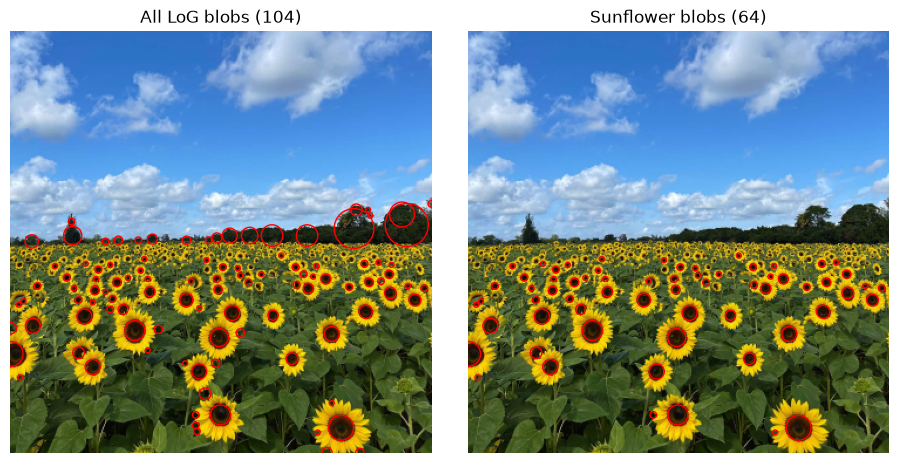

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(9.3, 4.6))
for ax, k, title in [(axes[0], np.ones(len(xs), bool), f'All LoG blobs ({len(xs)})'),
                     (axes[1], keep, f'Sunflower blobs ({keep.sum()})')]:
    ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
    for x, y, r in zip(xs[k], ys[k], radii[k]):
        ax.add_patch(plt.Circle((x, y), r, color='r', fill=False, linewidth=1))
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [92]:
xs_k, ys_k, ks_k, radii_k = xs[keep], ys[keep], ks[keep], radii[keep]
order = np.argsort(-radii_k)[:5]
print('  x    y   sigma  radius')
for o in order:
    print(f'{xs_k[o]:3d}  {ys_k[o]:3d}  {sigmas[ks_k[o]]:5.1f}  {radii_k[o]:6.2f}')

  x    y   sigma  radius
  0  275    7.5   10.61
282  338    7.5   10.61
179  327    6.0    8.49
106  255    6.0    8.49
178  261    5.5    7.78


$\textbf{Discussion:}$ The image is filtered with the scale-normalized LoG for $\sigma$ from 1 to 16 (step 0.5). A point is a blob if it is larger than all its neighbours in $x$, $y$ and $\sigma$ and above 0.2. The radius is $r = \sqrt{2}\sigma$. Only maxima are kept (not the squared response) because sunflower centres are dark blobs, which give positive LoG peaks.

LoG finds any dark blob, so it also picks the dark tree line and dark gaps between leaves (104 blobs). To keep only sunflowers, a blob is kept if the ring around it is mostly yellow (petals) and its centre is not green. This leaves 64 blobs, almost all on sunflower centres.

Largest circles: (282, 338) and (0, 275) with $\sigma = 7.5$, $r = 10.6$, then (179, 327) and (106, 255) with $\sigma = 6$, $r = 8.5$.

$\underline{\textbf{Question 2}}$

In [93]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Noisy point set conforming to a line and a circle
np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))  # All points

$\textbf{(a) Estimating the line with RANSAC}$

Line model: $ax + by = d$ with $\|[a, b]^\top\| = 1$. Error is the normal distance $|ax_i + by_i - d|$.

In [94]:
def line_from_points(p1, p2):
    # Unit normal [a, b] and distance d of the line through two points
    dx, dy = p2 - p1
    norm = np.hypot(dx, dy)
    a, b = dy / norm, -dx / norm
    return np.array([a, b, a * p1[0] + b * p1[1]])

def line_tls(params, pts):
    # Total least squares: sum of squared normal distances
    a, b, d = params
    return np.sum((a * pts[:, 0] + b * pts[:, 1] - d) ** 2)

# Constraint ||[a, b]|| = 1
cons = ({'type': 'eq', 'fun': lambda p: p[0] ** 2 + p[1] ** 2 - 1})

def line_consensus(params, pts, t):
    a, b, d = params
    return np.abs(a * pts[:, 0] + b * pts[:, 1] - d) < t

def ransac_line(pts, t, min_inliers, max_iterations):
    best_count = 0
    for _ in range(max_iterations):
        idx = np.random.choice(len(pts), 2, replace=False)  # minimal sample of 2 points
        model = line_from_points(pts[idx[0]], pts[idx[1]])
        inliers = line_consensus(model, pts, t)
        if inliers.sum() >= min_inliers and inliers.sum() > best_count:
            best_count = inliers.sum()
            best_sample, best_sample_model, best_inliers = pts[idx], model, inliers
    if best_count == 0:
        return None  # no sample reached the required consensus
    # Re-estimate the line from all inliers of the best sample
    res = minimize(line_tls, best_sample_model, args=(pts[best_inliers],), constraints=cons)
    return res.x, best_sample_model, best_sample, best_inliers

a = -0.721, b = -0.693, d = -1.572, ||[a, b]|| = 1.000
slope = -1.040, intercept = 2.269, inliers = 54


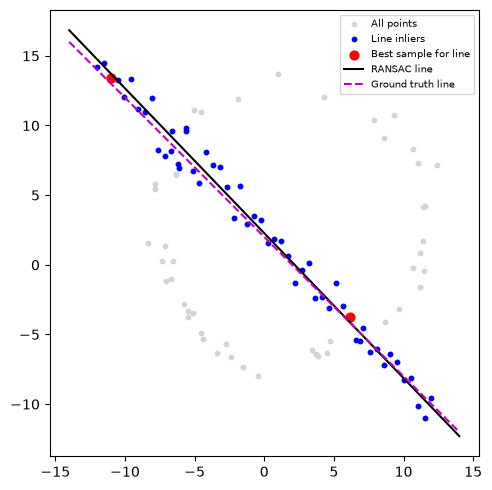

In [95]:
t_line = 1.4  # normal-distance threshold (1.96 x 0.71)
d_line = 40   # minimum consensus size
line_model, line_sample_model, line_sample, line_inliers = ransac_line(X, t_line, d_line, 100)

a_l, b_l, d_l = line_model  # (m, b are kept for the ground truth)
print(f'a = {a_l:.3f}, b = {b_l:.3f}, d = {d_l:.3f}, ||[a, b]|| = {np.hypot(a_l, b_l):.3f}')
print(f'slope = {-a_l / b_l:.3f}, intercept = {d_l / b_l:.3f}, inliers = {line_inliers.sum()}')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X[:, 0], X[:, 1], s=10, color='lightgray', label='All points')
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], s=10, color='b', label='Line inliers')
ax.scatter(line_sample[:, 0], line_sample[:, 1], s=40, color='r', label='Best sample for line')
x_ = np.array([-14, 14])
ax.plot(x_, (d_l - a_l * x_) / b_l, color='k', label='RANSAC line')
ax.plot(x_, m * x_ + b, 'm--', label='Ground truth line')
ax.set_aspect('equal')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

$\textbf{Parameter choice:}$ The line noise is $\sigma = 1$ in $y$, so the normal-distance noise is $1/\sqrt{2} \approx 0.71$. Using $t = 1.96\sigma$ (keeps about 95% of inliers) gives $t = 1.4$. The line has 50 points, so at least 40 inliers are required. Each sample uses 2 points. With 50% outliers and $p = 0.99$, $N = \log(1-p)/\log(1-(1-e)^s) \approx 16$ samples are enough. 100 are used to be safe. The final line is refitted on all inliers with $\|[a, b]^\top\| = 1$.

$\textbf{(b) Estimating the circle from the remnant with RANSAC}$

Circle model: centre $(x_c, y_c)$ and radius $r$. Error is the radial distance $\left|\sqrt{(x_i - x_c)^2 + (y_i - y_c)^2} - r\right|$.

In [96]:
def circle_from_points(p1, p2, p3):
    # Circumcircle of three points (None if they are nearly collinear)
    A = np.array([p2 - p1, p3 - p1]) * 2
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    if abs(np.linalg.det(A)) < 1e-6:
        return None
    centre = np.linalg.solve(A, rhs)
    return np.array([centre[0], centre[1], np.linalg.norm(p1 - centre)])

def radial_error(params, pts):
    xc, yc, rc = params
    return np.abs(np.hypot(pts[:, 0] - xc, pts[:, 1] - yc) - rc)

def circle_lsq(params, pts):
    return np.sum(radial_error(params, pts) ** 2)

def ransac_circle(pts, t, min_inliers, max_iterations):
    best_count = 0
    for _ in range(max_iterations):
        idx = np.random.choice(len(pts), 3, replace=False)  # minimal sample of 3 points
        model = circle_from_points(*pts[idx])
        if model is None:
            continue
        inliers = radial_error(model, pts) < t
        if inliers.sum() >= min_inliers and inliers.sum() > best_count:
            best_count = inliers.sum()
            best_sample, best_sample_model, best_inliers = pts[idx], model, inliers
    if best_count == 0:
        return None  # no sample reached the required consensus
    # Re-estimate the circle from all inliers of the best sample
    res = minimize(circle_lsq, best_sample_model, args=(pts[best_inliers],))
    return res.x, best_sample_model, best_sample, best_inliers

remnant points = 46
centre = (1.951, 3.046), radius = 9.873, inliers = 45


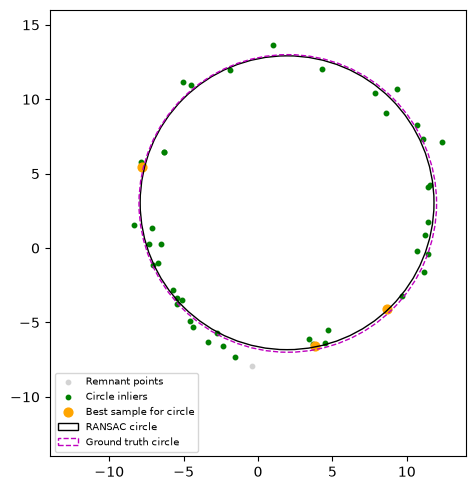

In [97]:
X_rem = X[~line_inliers]  # subtract the consensus of the best line

t_circ = 1.25  # radial-error threshold (2 x noise std r/16)
d_circ = 35    # minimum consensus size
circ_model, circ_sample_model, circ_sample, circ_inliers = ransac_circle(X_rem, t_circ, d_circ, 100)

xc, yc, rc = circ_model
print(f'remnant points = {len(X_rem)}')
print(f'centre = ({xc:.3f}, {yc:.3f}), radius = {rc:.3f}, inliers = {circ_inliers.sum()}')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_rem[:, 0], X_rem[:, 1], s=10, color='lightgray', label='Remnant points')
ax.scatter(X_rem[circ_inliers, 0], X_rem[circ_inliers, 1], s=10, color='g', label='Circle inliers')
ax.scatter(circ_sample[:, 0], circ_sample[:, 1], s=40, color='orange', label='Best sample for circle')
ax.add_patch(plt.Circle((xc, yc), rc, color='k', fill=False, label='RANSAC circle'))
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='m', fill=False, linestyle='--', label='Ground truth circle'))
ax.set_xlim(-14, 14)
ax.set_ylim(-14, 16)
ax.set_aspect('equal')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

$\textbf{Parameter choice:}$ The circle noise is $\sigma = r/16 = 0.625$, so $t = 1.96\sigma \approx 1.25$. Some circle points are removed with the line, so at least 35 inliers are required. Each sample uses 3 points. Few outliers remain, so only about 4 samples are needed. 100 are used. The final circle is refitted on all inliers.

$\textbf{(c) Line and circle estimated with RANSAC}$

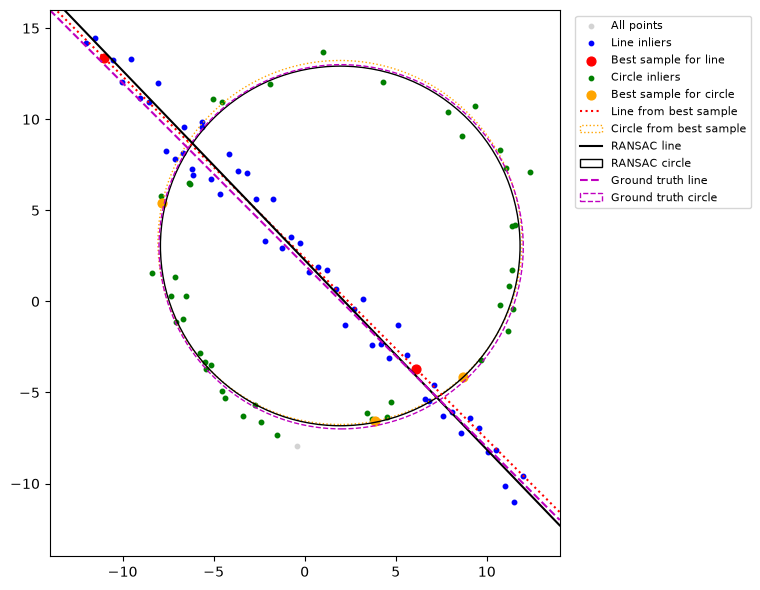

In [98]:
x_ = np.array([-14, 14])

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.scatter(X[:, 0], X[:, 1], s=10, color='lightgray', label='All points')
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], s=10, color='b', label='Line inliers')
ax.scatter(line_sample[:, 0], line_sample[:, 1], s=40, color='r', label='Best sample for line')
ax.scatter(X_rem[circ_inliers, 0], X_rem[circ_inliers, 1], s=10, color='g', label='Circle inliers')
ax.scatter(circ_sample[:, 0], circ_sample[:, 1], s=40, color='orange', label='Best sample for circle')

# Models estimated only from the best samples
a_s, b_s, d_s = line_sample_model
ax.plot(x_, (d_s - a_s * x_) / b_s, color='r', linestyle=':', label='Line from best sample')
ax.add_patch(plt.Circle(circ_sample_model[:2], circ_sample_model[2], color='orange', fill=False,
                        linestyle=':', label='Circle from best sample'))

# Best-fit models (re-estimated from all inliers)
ax.plot(x_, (d_l - a_l * x_) / b_l, color='k', label='RANSAC line')
ax.add_patch(plt.Circle((xc, yc), rc, color='k', fill=False, label='RANSAC circle'))

# Ground truth
ax.plot(x_, m * x_ + b, color='m', linestyle='--', label='Ground truth line')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='m', fill=False, linestyle='--', label='Ground truth circle'))

ax.set_xlim(-14, 14)
ax.set_ylim(-14, 16)
ax.set_aspect('equal')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

$\textbf{(d) Fitting the circle first}$

circle: centre = (1.90, 3.02), r = 9.88, inliers = 57
line points taken by the circle = 9 (line-first: circle points taken by the line = 4)
line points left = 41
line after circle: slope = -1.047, inliers = 41
seed 43 circle: r = 1300.6, inliers = 52 (line points: 49)


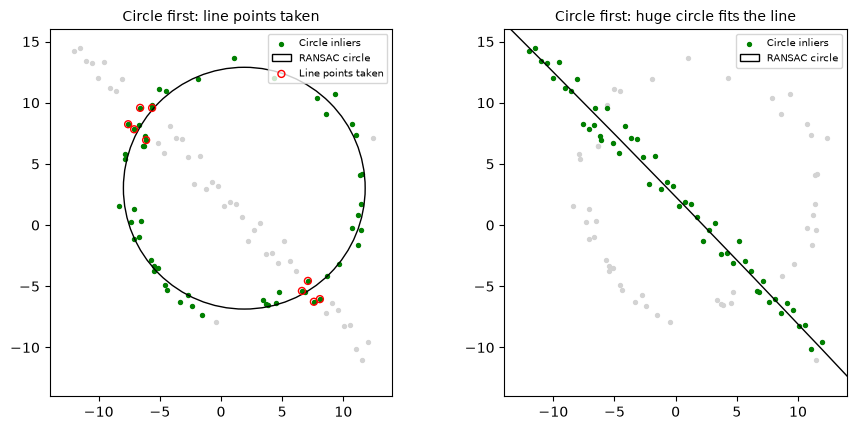

In [99]:
# Case 1: circle first on all points, then the line on the remnant
np.random.seed(1)
c_model, _, _, c_inl = ransac_circle(X, t_circ, d_circ, 100)
print(f'circle: centre = ({c_model[0]:.2f}, {c_model[1]:.2f}), r = {c_model[2]:.2f}, inliers = {c_inl.sum()}')
print(f'line points taken by the circle = {c_inl[half_n:].sum()} '
      f'(line-first: circle points taken by the line = {line_inliers[:half_n].sum()})')
X_rem2 = X[~c_inl]
print(f'line points left = {(~c_inl[half_n:]).sum()}')
line2 = ransac_line(X_rem2, t_line, d_line, 100)
print('line after circle:', 'failed' if line2 is None else f'slope = {-line2[0][0] / line2[0][1]:.3f}, inliers = {line2[3].sum()}')

# Case 2: a seed where a huge circle fits the line points
np.random.seed(43)
big_model, _, _, big_inl = ransac_circle(X, t_circ, d_circ, 100)
print(f'seed 43 circle: r = {big_model[2]:.1f}, inliers = {big_inl.sum()} (line points: {big_inl[half_n:].sum()})')

fig, axes = plt.subplots(1, 2, figsize=(9.3, 4.4))
for ax, inl, model, title in [(axes[0], c_inl, c_model, 'Circle first: line points taken'),
                              (axes[1], big_inl, big_model, 'Circle first: huge circle fits the line')]:
    ax.scatter(X[:, 0], X[:, 1], s=8, color='lightgray')
    ax.scatter(X[inl, 0], X[inl, 1], s=8, color='g', label='Circle inliers')
    ax.add_patch(plt.Circle(model[:2], model[2], color='k', fill=False, label='RANSAC circle'))
    ax.set_xlim(-14, 14)
    ax.set_ylim(-14, 16)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, loc='upper right')
taken = c_inl.copy()
taken[:half_n] = False
axes[0].scatter(X[taken, 0], X[taken, 1], s=25, facecolors='none', edgecolors='r', label='Line points taken')
axes[0].legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

$\textbf{Discussion:}$ If the circle is fitted first, its inlier band overlaps the line where the line crosses the circle, so it takes 9 line points (the line, fitted first, takes only 4 circle points). These wrong points pull the circle fit, and fewer points are left for the line. Also, a very large circle looks almost straight, so RANSAC can return a "circle" that is really the line (seed 43: $r \approx 1300$, 49 of its 52 inliers are line points). So it is better to fit the simpler, thinner model (the line) first.

$\underline{\textbf{Question 3}}$

In [100]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def select_points(im, n=4):
    # Click n points on the image (order: top-left, top-right, bottom-right, bottom-left)
    pts = []
    def on_click(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(pts) < n:
            pts.append([x, y])
            cv.circle(disp, (x, y), 5, (0, 0, 255), -1)
            cv.imshow('Select points', disp)
    disp = im.copy()
    cv.imshow('Select points', disp)
    cv.setMouseCallback('Select points', on_click)
    while len(pts) < n:
        cv.waitKey(20)
    cv.destroyAllWindows()
    return np.array(pts, dtype=np.float32)

def overlay(im_dst, im_src, pts_dst, alpha=0.8):
    # Homography mapping the corners of im_src to the clicked points, then warp and blend
    h, w = im_src.shape[:2]
    pts_src = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=np.float32)
    H, _ = cv.findHomography(pts_src, pts_dst)
    size = (im_dst.shape[1], im_dst.shape[0])
    warped = cv.warpPerspective(im_src, H, size)
    mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, size) > 0
    blended = cv.addWeighted(im_dst, 1 - alpha, warped, alpha, 0)
    out = im_dst.copy()
    out[mask] = blended[mask]  # blend only inside the warped flag region
    return out, H

H =
 [[2.299e-01 0.000e+00 1.500e+02]
 [6.760e-02 2.138e-01 2.250e+02]
 [1.000e-04 0.000e+00 1.000e+00]]


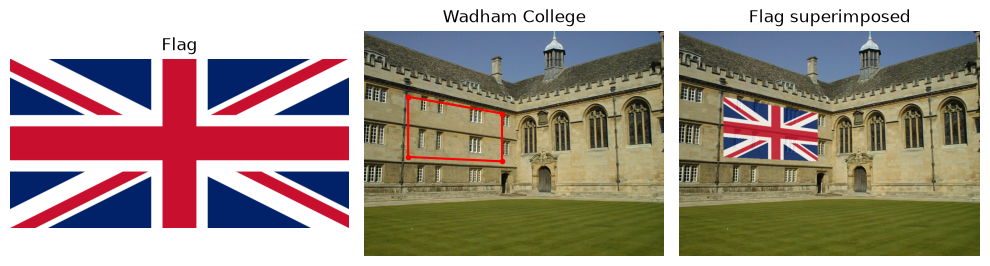

In [101]:
im = cv.imread('images/wadham.jpg')
flag = cv.imread('images/flag.png')

# pts = select_points(im)  # uncomment to click the points again
pts = np.array([[150, 225], [470, 282], [470, 445], [150, 430]], dtype=np.float32)  # clicked points
result, H = overlay(im, flag, pts)
print('H =\n', np.round(H, 4))

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), gridspec_kw={'width_ratios': [1.5, 1.33, 1.33]})
for ax, (img, title) in zip(axes, [(flag, 'Flag'), (im, 'Wadham College'), (result, 'Flag superimposed')]):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
axes[1].plot(*np.vstack([pts, pts[:1]]).T, 'r.-')
plt.tight_layout()
plt.show()

$\textbf{Discussion:}$ Four corners of a flat part of the left wall are clicked (top-left, top-right, bottom-right, bottom-left). `cv.findHomography` maps the four corners of the flag to these points, and `cv.warpPerspective` warps the flag onto the wall. The flag is blended with $\alpha = 0.8$ only inside the warped region, so a little of the wall still shows through. The flag gets smaller towards the right, following the perspective of the wall. This works because the wall is flat, and a homography is exact for a plane.

$\textbf{Own image pair 1: a photo on a laptop screen}$

H =
 [[ 2.366e-01  2.090e-02  3.130e+02]
 [ 2.410e-02  3.134e-01  5.500e+01]
 [-2.000e-04  1.000e-04  1.000e+00]]


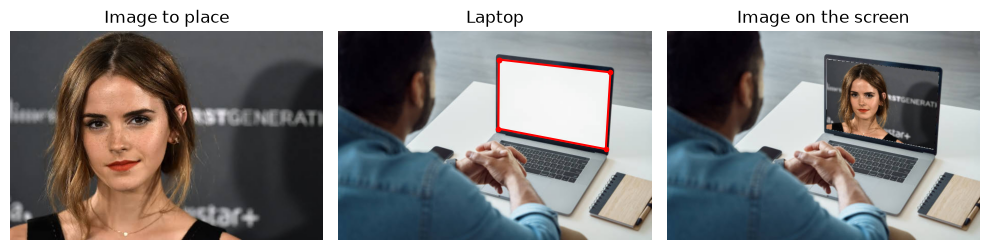

In [102]:
laptop = cv.imread('images/laptop.jpg')
emma = cv.imread('images/emma.jpg')

# pts = select_points(laptop)  # uncomment to click the points again
pts_laptop = np.array([[313, 55], [531, 80], [522, 230], [312, 190]], dtype=np.float32)  # screen corners
result_laptop, H_laptop = overlay(laptop, emma, pts_laptop, alpha=1.0)  # opaque, like a real display
print('H =\n', np.round(H_laptop, 4))

fig, axes = plt.subplots(1, 3, figsize=(10, 2.6))
for ax, (img, title) in zip(axes, [(emma, 'Image to place'), (laptop, 'Laptop'), (result_laptop, 'Image on the screen')]):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
axes[1].plot(*np.vstack([pts_laptop, pts_laptop[:1]]).T, 'r.-')
plt.tight_layout()
plt.show()

$\textbf{Rationale:}$ A laptop screen is flat with four clear corners, and it is seen at an angle, so the homography has real perspective to correct. This is like a product mockup (showing a picture on a device). $\alpha = 1$ so the picture looks like it is on the screen.

$\textbf{Own image pair 2: an advert on a roadside billboard}$

H =
 [[ 6.159e-01 -6.400e-03  4.610e+02]
 [ 1.120e-02  4.510e-01  1.340e+02]
 [ 0.000e+00 -0.000e+00  1.000e+00]]


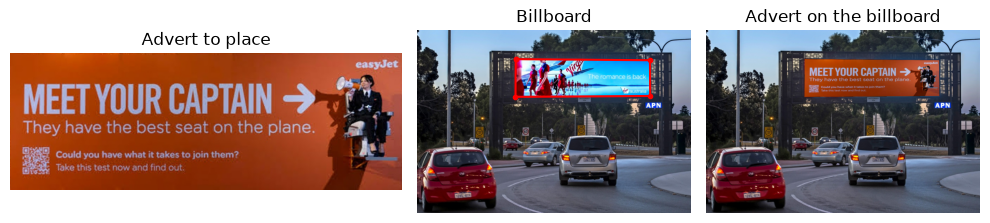

In [103]:
billboard = cv.imread('images/billboard.jpg')
ad = cv.imread('images/easyjet_ad.jpg')

# pts = select_points(billboard)  # uncomment to click the points again
pts_board = np.array([[461, 134], [1088, 139], [1089, 306], [460, 310]], dtype=np.float32)  # screen corners
result_board, H_board = overlay(billboard, ad, pts_board, alpha=1.0)
print('H =\n', np.round(H_board, 4))

fig, axes = plt.subplots(1, 3, figsize=(10, 2.4), gridspec_kw={'width_ratios': [1.43, 1, 1]})
for ax, (img, title) in zip(axes, [(ad, 'Advert to place'), (billboard, 'Billboard'), (result_board, 'Advert on the billboard')]):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
axes[1].plot(*np.vstack([pts_board, pts_board[:1]]).T, 'r.-')
plt.tight_layout()
plt.show()

$\textbf{Rationale:}$ A billboard is a large flat surface seen from below, a different view from the laptop. This shows how an advert could be previewed on a real billboard. The advert was first cut out of a wall photo and straightened with `cv.getPerspectiveTransform`. The screen is wider than the advert, so the advert is stretched a little.

$\underline{\textbf{Question 4}}$

$\textbf{(a) SIFT features in the template and a PCB image}$

In [104]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Half resolution keeps SIFT fast while leaving plenty of detail
template = cv.imread('images/pcbs/AECC1.jpg', cv.IMREAD_REDUCED_COLOR_2)
pcb = cv.imread('images/pcbs/AECC2.jpg', cv.IMREAD_REDUCED_COLOR_2)
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

sift = cv.SIFT_create()
kp_t, des_t = sift.detectAndCompute(template_gray, None)
kp_p, des_p = sift.detectAndCompute(cv.cvtColor(pcb, cv.COLOR_BGR2GRAY), None)
print(f'template keypoints = {len(kp_t)}, AECC2 keypoints = {len(kp_p)}')

template keypoints = 6990, AECC2 keypoints = 6900


$\textbf{(b) Matching with BFMatcher and homography with RANSAC}$

good matches = 3176, RANSAC inliers = 2870
H =
 [[ 1.00020e+00 -1.51000e-02  1.61576e+01]
 [ 1.64000e-02  9.99600e-01 -8.87140e+00]
 [ 0.00000e+00  0.00000e+00  1.00000e+00]]


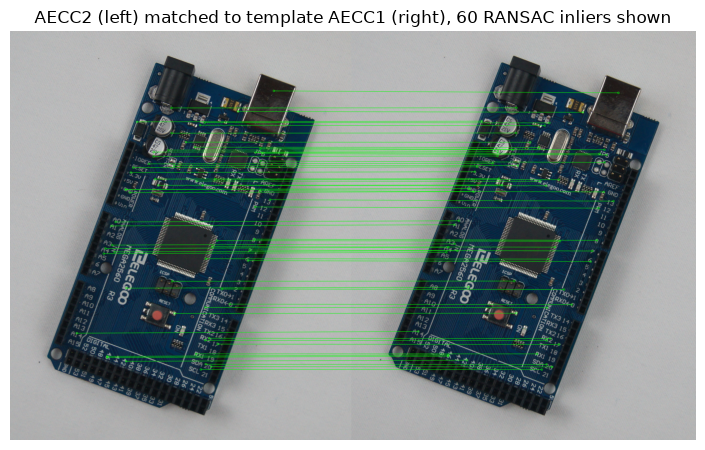

In [105]:
def match_and_homography(kp1, des1, kp2, des2, ratio=0.75):
    # Brute-force matching with Lowe's ratio test, then a RANSAC homography (image -> template)
    bf = cv.BFMatcher()
    good = [m for m, n in bf.knnMatch(des1, des2, k=2) if m.distance < ratio * n.distance]
    src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)
    return H, good, mask.ravel().astype(bool)

H, good, inliers = match_and_homography(kp_p, des_p, kp_t, des_t)
print(f'good matches = {len(good)}, RANSAC inliers = {inliers.sum()}')
print('H =\n', np.round(H, 4))

# Draw a random subset of the RANSAC inlier matches so the lines stay readable
np.random.seed(0)
inlier_matches = [m for m, keep in zip(good, inliers) if keep]
shown = [inlier_matches[i] for i in np.random.choice(len(inlier_matches), 60, replace=False)]
match_img = cv.drawMatches(pcb, kp_p, template, kp_t, shown, None, matchColor=(0, 255, 0),
                           flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(9.3, 4.6))
plt.imshow(cv.cvtColor(match_img, cv.COLOR_BGR2RGB))
plt.title('AECC2 (left) matched to template AECC1 (right), 60 RANSAC inliers shown')
plt.axis('off')
plt.tight_layout()
plt.show()

$\textbf{Parameter choice:}$ A match is kept only if its distance is less than 0.75 times the second-best match (Lowe's ratio test), which removes unclear matches. The homography is found with RANSAC (5 pixel threshold), which removes the remaining wrong matches.

$\textbf{(c) Warping to the template and computing the difference}$

mean absolute difference = 2.68


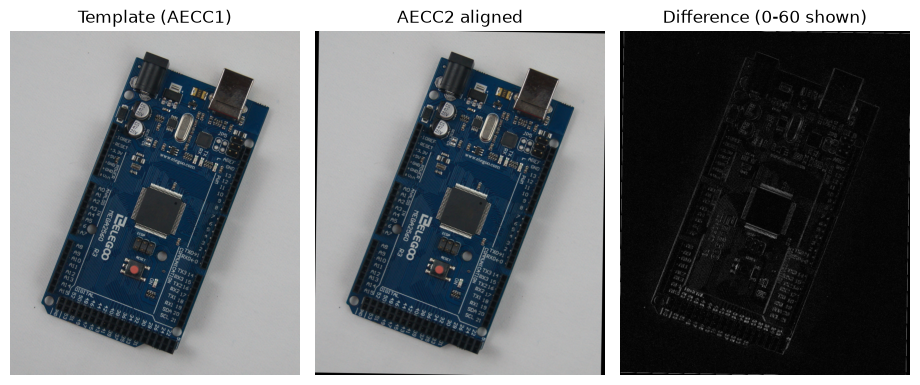

In [106]:
def align_and_diff(im, H, template_gray):
    # Warp the PCB image into the template frame and take the absolute difference
    h, w = template_gray.shape
    aligned = cv.warpPerspective(im, H, (w, h))
    valid = cv.warpPerspective(np.full(im.shape[:2], 255, np.uint8), H, (w, h)) > 0
    diff = cv.absdiff(cv.cvtColor(aligned, cv.COLOR_BGR2GRAY), template_gray)
    diff[~valid] = 0  # ignore the area the warped image does not cover
    return aligned, diff

aligned, diff = align_and_diff(pcb, H, template_gray)
print(f'mean absolute difference = {diff.mean():.2f}')

fig, axes = plt.subplots(1, 3, figsize=(9.3, 3.9))
axes[0].imshow(cv.cvtColor(template, cv.COLOR_BGR2RGB))
axes[0].set_title('Template (AECC1)')
axes[1].imshow(cv.cvtColor(aligned, cv.COLOR_BGR2RGB))
axes[1].set_title('AECC2 aligned')
axes[2].imshow(diff, cmap='gray', vmin=0, vmax=60)  # stretched so small differences are visible
axes[2].set_title('Difference (0-60 shown)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

$\textbf{(d) All PCB images}$

image   keypoints  good  inliers  mean diff
AAAA1       1428    54       26      25.23
ADAD1       5490   384      213      30.55
AECC2       6900  3176     2870       2.68
AECC3       6747  3675     3369       2.42
AECC4       7239  3255     2928       3.31


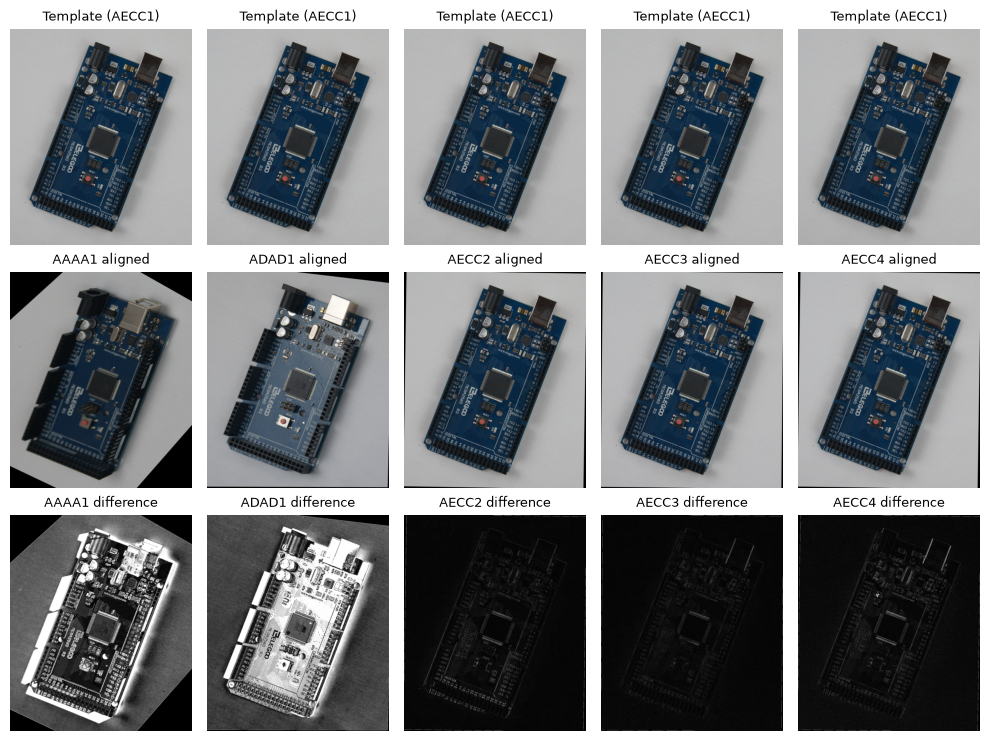

In [107]:
names = ['AAAA1', 'ADAD1', 'AECC2', 'AECC3', 'AECC4']
results = []
match_imgs = []
print('image   keypoints  good  inliers  mean diff')
for name in names:
    im = cv.imread(f'images/pcbs/{name}.jpg', cv.IMREAD_REDUCED_COLOR_2)
    kp, des = sift.detectAndCompute(cv.cvtColor(im, cv.COLOR_BGR2GRAY), None)
    H_i, good_i, inl_i = match_and_homography(kp, des, kp_t, des_t)
    aligned_i, diff_i = align_and_diff(im, H_i, template_gray)
    results.append((name, aligned_i, diff_i))
    # keep a picture of up to 40 inlier matches for this board
    inl_m = [mm for mm, keep in zip(good_i, inl_i) if keep]
    pick = np.random.default_rng(0).choice(len(inl_m), min(40, len(inl_m)), replace=False)
    match_imgs.append((name, cv.drawMatches(im, kp, template, kp_t, [inl_m[p] for p in pick], None,
                                            matchColor=(0, 255, 0), flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)))
    print(f'{name}   {len(kp):8d}  {len(good_i):4d}  {inl_i.sum():7d}  {diff_i.mean():9.2f}')

fig, axes = plt.subplots(3, len(names), figsize=(10, 7.5))
for j, (name, aligned_i, diff_i) in enumerate(results):
    axes[0, j].imshow(cv.cvtColor(template, cv.COLOR_BGR2RGB))
    axes[0, j].set_title('Template (AECC1)', fontsize=9)
    axes[1, j].imshow(cv.cvtColor(aligned_i, cv.COLOR_BGR2RGB))
    axes[1, j].set_title(f'{name} aligned', fontsize=9)
    axes[2, j].imshow(diff_i, cmap='gray', vmin=0, vmax=60)
    axes[2, j].set_title(f'{name} difference', fontsize=9)
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

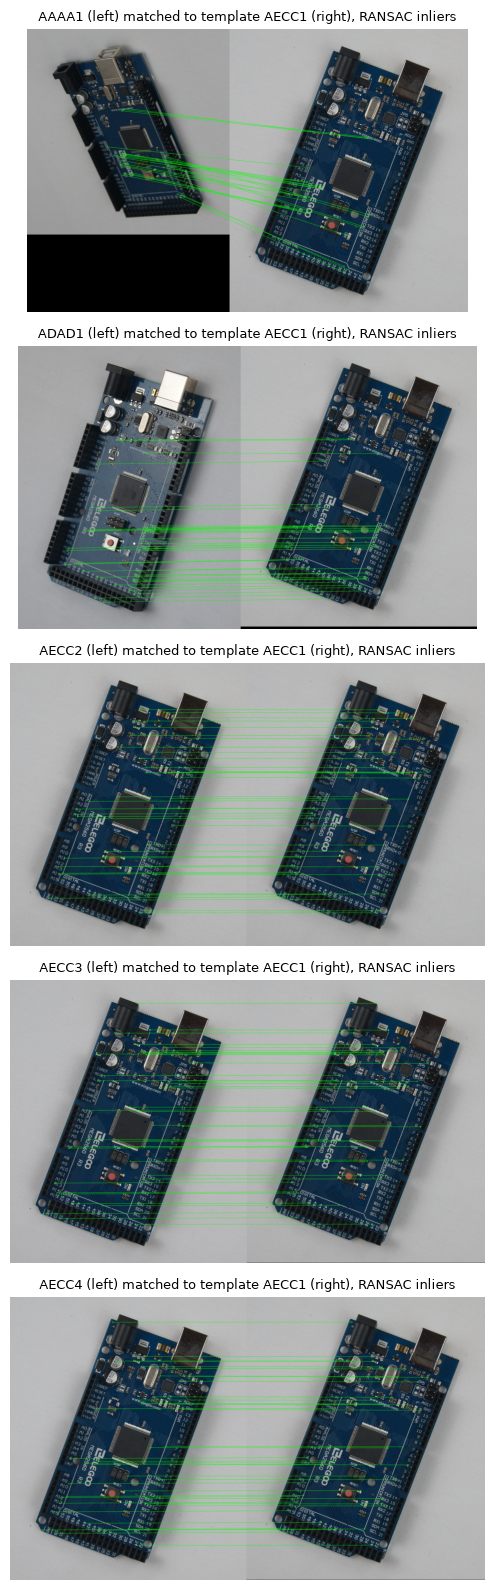

In [108]:
fig, axes = plt.subplots(len(match_imgs), 1, figsize=(8, 3.2 * len(match_imgs)))
for ax, (name, mimg) in zip(axes, match_imgs):
    ax.imshow(cv.cvtColor(mimg, cv.COLOR_BGR2RGB))
    ax.set_title(f'{name} (left) matched to template AECC1 (right), RANSAC inliers', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

$\textbf{(e) Why the USB port, capacitors and reset button show high difference}$

A homography is exact only for one plane, here the board surface. The USB port, capacitors, reset button and pin headers stick out of this plane, so when the camera moves slightly they shift differently from the board (parallax) and do not line up after warping. They are also shiny or tall, so reflections and shadows change between photos. AECC2–AECC4 have a small mean difference (about 2–3). AAAA1 and ADAD1 are much higher (25–31) because of different lighting, lower resolution (AAAA1) and a different board colour (ADAD1), not because of bad alignment.